# Дослідження ринку нерухомості: Ames Housing (2006–2010)

**Курсова робота** з дисципліни «Мови програмування для аналізу даних».

**Мета:** визначити, які характеристики будинків і умови продажу формують ціну житла в м. Еймс (штат Айова, США) у 2006–2010 роках.

**Дослідницькі питання**
1. Як ціна відрізняється між районами і які райони найдорожчі?
2. Як ціна залежить від площі, якості та віку будинку?
3. Як змінювалися ціни та кількість продажів у часі, зокрема в період кризи 2008–2009 років?
4. Чи впливають на ціну умови продажу (`SaleCondition`) і тип будинку?
5. Чи є аномальні угоди, що спотворюють результати?

**Дані:** Ames Housing (Kaggle, *House Prices – Advanced Regression Techniques*), файл `train.csv`. Опис ознак — `data/raw/data_description.txt`.

## 0. Запуск у Google Colab (лише для Colab)

In [1]:
# У Colab ноутбук відкривається без решти файлів проєкту, тому клонуємо репозиторій.
# Локально (Jupyter) ця комірка нічого не робить.
import os
if "COLAB_GPU" in os.environ or os.path.exists("/content"):
    if not os.path.exists("/content/ames-housing-analysis"):
        !git clone https://github.com/Denis8870/ames-housing-analysis.git /content/ames-housing-analysis
    %cd /content/ames-housing-analysis/notebooks

## 1. Підготовка середовища

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RAW_PATH = Path("../data/raw/train.csv")
PROCESSED_PATH = Path("../data/processed/ames_clean.csv")
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Завантаження даних

In [3]:
df_raw = pd.read_csv(RAW_PATH)
print(f"Записів: {df_raw.shape[0]}, ознак: {df_raw.shape[1]}")
df_raw.head()

Записів: 1460, ознак: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Первинне дослідження

Перевіряємо розмір таблиці, типи змінних і описову статистику цільового показника `SalePrice` (ціна продажу, USD).

In [4]:
print("Типи змінних:")
print(df_raw.dtypes.astype(str).value_counts())
print()
df_raw.info(max_cols=0)

Типи змінних:
str        43
int64      35
float64     3
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 81 entries, Id to SalePrice
dtypes: float64(3), int64(35), str(43)
memory usage: 924.0 KB


In [5]:
df_raw["SalePrice"].describe()

count     1,460.00
mean    180,921.20
std      79,442.50
min      34,900.00
25%     129,975.00
50%     163,000.00
75%     214,000.00
max     755,000.00
Name: SalePrice, dtype: float64

In [6]:
# Кількість продажів за роками та унікальних районів
print(df_raw["YrSold"].value_counts().sort_index())
print("\nУнікальних районів:", df_raw["Neighborhood"].nunique())

YrSold
2006    314
2007    329
2008    304
2009    338
2010    175
Name: count, dtype: int64

Унікальних районів: 25


**Висновок.** Таблиця містить 1460 продажів і 81 ознаку: числові (площі, рік побудови, кількість кімнат) та категоріальні (район, тип будинку, умови продажу). Часова ознака — `YrSold` і `MoSold` (2006–2010). Для групування придатні `Neighborhood`, `BldgType`, `SaleCondition`, `YrSold`; ключ — `Id`.

## 4. Попереднє опрацювання даних

### 4.1. Дублікати

In [7]:
dup_full = df_raw.duplicated().sum()
dup_id = df_raw["Id"].duplicated().sum()
print(f"Повних дублікатів: {dup_full}")
print(f"Дублікатів за Id: {dup_id}")

Повних дублікатів: 0
Дублікатів за Id: 0


### 4.2. Пропущені значення

Згідно з `data_description.txt`, у багатьох категоріальних ознаках значення `NA` означає **відсутність об'єкта** (немає басейну, гаража, підвалу), а не втрачені дані. Pandas за замовчуванням читає рядок `NA` як `NaN`, тому спершу розділимо «структурні» пропуски й справжні.

In [8]:
missing_before = df_raw.isna().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)
summary_before = pd.DataFrame({
    "Пропусків": missing_before,
    "Частка, %": (missing_before / len(df_raw) * 100).round(1),
})
summary_before

,Пропусків,"Частка, %"
PoolQC,1453,99.50
MiscFeature,1406,96.30
Alley,1369,93.80
Fence,1179,80.80
MasVnrType,872,59.70
FireplaceQu,690,47.30
LotFrontage,259,17.70
GarageType,81,5.50
GarageYrBlt,81,5.50
GarageFinish,81,5.50


In [9]:
# Ознаки, де NA = «об'єкта немає» (за data_description.txt)
none_means_absent = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]
# Додатково: MasVnrType — у даних значення "None" (немає облицювання) прочиталось як NaN
none_means_absent_all = none_means_absent + ["MasVnrType"]

df = df_raw.copy()
for col in none_means_absent_all:
    df[col] = df[col].fillna("None")

# Пов'язана числова ознака: якщо облицювання немає, його площа = 0
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Рік побудови гаража: пропуск там, де гаража немає. Лишаємо NaN
# (підставляти рік було б некоректно), але додаємо позначку наявності гаража.
df["HasGarage"] = (df["GarageType"] != "None").astype(int)

# Електрика: 1 справжній пропуск -> мода (категорія, що переважає)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

# LotFrontage: 259 справжніх пропусків (≈18%). Заповнюємо медіаною по району,
# бо ширина ділянки типова для району; видаляти 18% записів недоцільно.
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

In [10]:
missing_after = df.isna().sum()
missing_after = missing_after[missing_after > 0]
print("Залишилось пропусків (лише GarageYrBlt — гаража немає):")
print(missing_after)
print()
print(f"Пропусків усього: до = {int(df_raw.isna().sum().sum())}, після = {int(df.isna().sum().sum())}")
print(f"Колонок із пропусками: до = {int((df_raw.isna().sum() > 0).sum())}, після = {int((df.isna().sum() > 0).sum())}")

Залишилось пропусків (лише GarageYrBlt — гаража немає):
GarageYrBlt    81
dtype: int64

Пропусків усього: до = 7829, після = 81
Колонок із пропусками: до = 19, після = 1


**Висновок.** Більшість пропусків були не втратою даних, а кодом «немає»: їх замінено на категорію `"None"`. Справжніх пропусків було два типи: `LotFrontage` (заповнено медіаною по району) і `Electrical` (1 запис, заповнено модою). `GarageYrBlt` лишено порожнім для будинків без гаража, а наявність гаража зафіксовано ознакою `HasGarage`.

### 4.3. Типи даних

In [11]:
# MSSubClass — код типу будинку, а не число; YrSold/MoSold беруть участь у групуванні як категорії
df["MSSubClass"] = df["MSSubClass"].astype("category")

# Дата продажу для аналізу динаміки
df["SaleDate"] = pd.to_datetime(
    dict(year=df["YrSold"], month=df["MoSold"], day=1)
)
df[["YrSold", "MoSold", "SaleDate"]].head()

,YrSold,MoSold,SaleDate
0,2008,2,2008-02-01
1,2007,5,2007-05-01
2,2008,9,2008-09-01
3,2006,2,2006-02-01
4,2008,12,2008-12-01


`MSSubClass` — це код (20, 30, 60…), арифметика з ним не має сенсу, тому його перетворено на категорію. Із `YrSold` і `MoSold` сформовано `SaleDate` для аналізу динаміки.

### 4.4. Викиди

Викиди не завжди є помилками, тому їх **не видаляємо автоматично**: спершу оцінюємо кількість за методом міжквартильного розмаху (IQR) та розглядаємо найпідозріліші записи.

In [12]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < low) | (series > high)
    return mask.sum(), low, high

rows = []
for col in ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"]:
    n, low, high = iqr_outliers(df[col])
    rows.append({"Ознака": col, "Викидів": n, "Частка, %": round(n / len(df) * 100, 1),
                 "Нижня межа": round(low), "Верхня межа": round(high)})
pd.DataFrame(rows)

,Ознака,Викидів,"Частка, %",Нижня межа,Верхня межа
0,SalePrice,61,4.20,3938,340038
1,GrLivArea,31,2.10,159,2748
2,LotArea,69,4.70,1482,17674
3,TotalBsmtSF,61,4.20,42,2052
4,GarageArea,21,1.40,-28,938


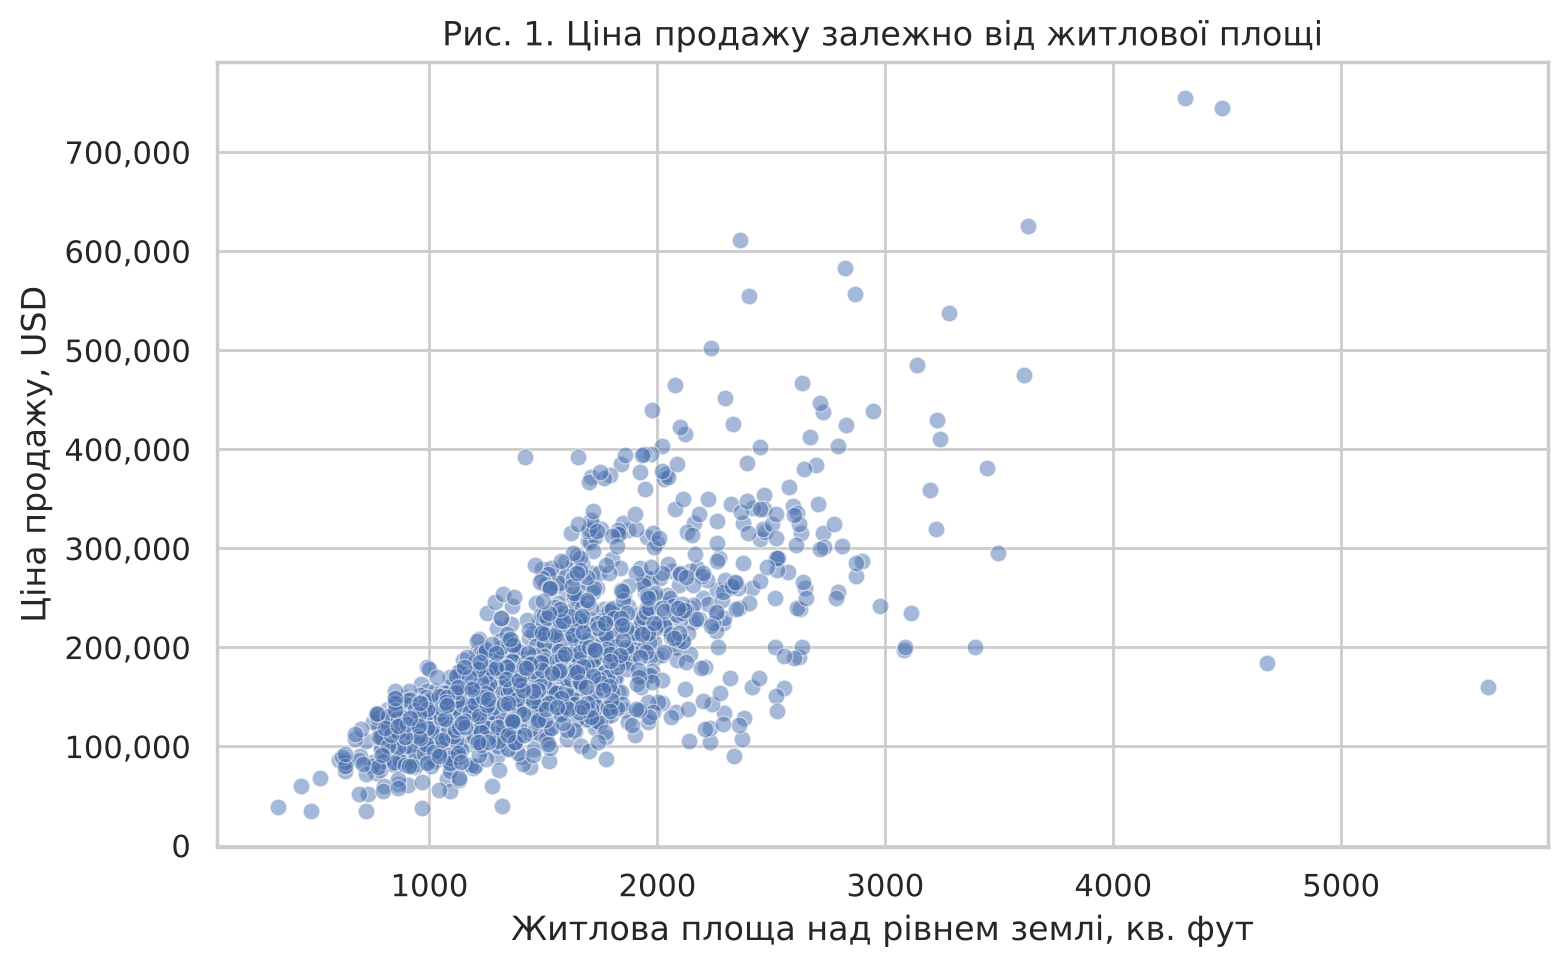

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.5, ax=ax)
ax.set_title("Рис. 1. Ціна продажу залежно від житлової площі")
ax.set_xlabel("Житлова площа над рівнем землі, кв. фут")
ax.set_ylabel("Ціна продажу, USD")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_price_vs_area.png", dpi=150)
plt.show()

In [14]:
# Підозрілі угоди: дуже велика площа за дуже низькою ціною
suspicious = df[(df["GrLivArea"] > 4000)][["Id", "Neighborhood", "GrLivArea", "SalePrice", "SaleCondition"]]
suspicious

,Id,Neighborhood,GrLivArea,SalePrice,SaleCondition
523,524,Edwards,4676,184750,Partial
691,692,NoRidge,4316,755000,Normal
1182,1183,NoRidge,4476,745000,Abnorml
1298,1299,Edwards,5642,160000,Partial


**Висновок.** За правилом IQR у `SalePrice` 61 викид (4,2%), що природно для ринку нерухомості: дорогі будинки існують реально, тому їх не видаляємо. Окремо розглянуто 4 будинки з площею понад 4000 кв. фут. Два з них (`Id` 692 і 1183, район NoRidge) коштують понад \$740 000, що узгоджується з їхньою площею, тож це реальні дорогі продажі. Інші два (`Id` 524 і 1299, район Edwards) мають ціни \$184 750 і \$160 000 за площу 4676 і 5642 кв. фут, і в обох `SaleCondition = Partial`: будинок продано до завершення будівництва, тому ціна не відображає повну вартість. Саме ці дві угоди позначаємо прапорцем `IsAnomaly` і далі порівнюємо результати з ними та без них (питання 5), а не вилучаємо мовчки.

In [15]:
df["IsAnomaly"] = ((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)).astype(int)
print("Позначено аномальних угод:", df["IsAnomaly"].sum())

Позначено аномальних угод: 2


### 4.5. Підсумок очищення і збереження

In [16]:
cleaning_report = pd.DataFrame({
    "Показник": [
        "Записів", "Ознак (було)", "Ознак (стало)", "Повних дублікатів",
        "Пропусків до очищення", "Пропусків після очищення", "Записів, позначених як аномалії",
    ],
    "Значення": [
        len(df), df_raw.shape[1], df.shape[1], int(dup_full),
        int(df_raw.isna().sum().sum()), int(df.isna().sum().sum()), int(df["IsAnomaly"].sum()),
    ],
})
cleaning_report

,Показник,Значення
0,Записів,1460
1,Ознак (було),81
2,Ознак (стало),84
3,Повних дублікатів,0
4,Пропусків до очищення,7829
5,Пропусків після очищення,81
6,"Записів, позначених як аномалії",2


In [17]:
df.to_csv(PROCESSED_PATH, index=False)
print("Збережено:", PROCESSED_PATH)

Збережено: ../data/processed/ames_clean.csv


## 5. Створення аналітичних ознак

Нові ознаки допомагають відповісти на дослідницькі питання 2–4.

| Ознака | Формула | Навіщо |
|---|---|---|
| `HouseAge` | `YrSold − YearBuilt` | вік будинку на момент продажу (питання 2) |
| `PricePerSqFt` | `SalePrice / GrLivArea` | ціна за кв. фут: порівнювати будинки різного розміру (питання 1, 2) |
| `TotalSF` | підвал + 1-й + 2-й поверхи | загальна площа будинку |
| `WasRemodeled` | `YearRemodAdd > YearBuilt` | чи був ремонт/добудова |
| `AgeGroup` | інтервали віку (`cut`) | категорії для порівняння груп |
| `SizeCategory` | квартилі `GrLivArea` (`qcut`) | категорії розміру: малий / середній / великий / дуже великий |

In [18]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["PricePerSqFt"] = df["SalePrice"] / df["GrLivArea"]
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["WasRemodeled"] = (df["YearRemodAdd"] > df["YearBuilt"]).astype(int)

df["AgeGroup"] = pd.cut(
    df["HouseAge"], bins=[-1, 5, 20, 50, 200],
    labels=["Новий (до 5 р.)", "5–20 р.", "20–50 р.", "Старий (50+ р.)"],
)
df["SizeCategory"] = pd.qcut(
    df["GrLivArea"], q=4, labels=["Малий", "Середній", "Великий", "Дуже великий"],
)
df[["HouseAge", "PricePerSqFt", "TotalSF", "WasRemodeled", "AgeGroup", "SizeCategory"]].head()

,HouseAge,PricePerSqFt,TotalSF,WasRemodeled,AgeGroup,SizeCategory
0,5,121.93,2566,0,Новий (до 5 р.),Великий
1,31,143.82,2524,0,20–50 р.,Середній
2,7,125.14,2706,1,5–20 р.,Дуже великий
3,91,81.54,2473,1,Старий (50+ р.),Великий
4,8,113.74,3343,0,5–20 р.,Дуже великий


In [19]:
# Перевірка коректності: чи немає від'ємного віку (продаж до побудови)
print("Мінімальний вік:", df["HouseAge"].min(), "| записів з віком < 0:", (df["HouseAge"] < 0).sum())
print()
print(df["AgeGroup"].value_counts().sort_index())
print()
print(df["SizeCategory"].value_counts().sort_index())

Мінімальний вік: 0 | записів з віком < 0: 0

AgeGroup
Новий (до 5 р.)    310
5–20 р.            254
20–50 р.           457
Старий (50+ р.)    439
Name: count, dtype: int64

SizeCategory
Малий           365
Середній        366
Великий         364
Дуже великий    365
Name: count, dtype: int64


## 6. Описова статистика, групування й ранжування

### 6.1. Описова статистика ціни та ключових ознак

In [20]:
key_cols = ["SalePrice", "PricePerSqFt", "GrLivArea", "HouseAge", "OverallQual"]
stats = df[key_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
stats["Q1"] = df[key_cols].quantile(0.25)
stats["Q3"] = df[key_cols].quantile(0.75)
stats["Асиметрія"] = df[key_cols].skew()
stats

,count,mean,median,std,min,max,Q1,Q3,Асиметрія
SalePrice,"1,460.00","180,921.20","163,000.00","79,442.50","34,900.00","755,000.00","129,975.00","214,000.00",1.88
PricePerSqFt,"1,460.00",120.57,120.10,31.39,28.36,276.25,99.82,138.70,0.38
GrLivArea,"1,460.00","1,515.46","1,464.00",525.48,334.00,"5,642.00","1,129.50","1,776.75",1.37
HouseAge,"1,460.00",36.55,35.00,30.25,0.00,136.00,8.00,54.00,0.61
OverallQual,"1,460.00",6.10,6.00,1.38,1.00,10.00,5.00,7.00,0.22


**Висновок** Середня ціна продажу (\$180 921) вища за медіану (\$163 000), а асиметрія додатна (1,88). Це означає, що розподіл цін скошений вправо: невелика кількість дорогих будинків (максимум \$755 000) підтягує середнє вгору, тоді як половина будинків коштує менше \$163 000. Для опису типової ціни тому надійніша медіана. Ціна за кв. фут розподілена симетричніше (асиметрія 0,38), а її медіана становить \$120,10.

### 6.2. Ціна за районами (питання 1)

In [21]:
by_nbhd = (
    df.groupby("Neighborhood")
      .agg(Продажів=("Id", "count"),
           Середня_ціна=("SalePrice", "mean"),
           Медіанна_ціна=("SalePrice", "median"),
           Ціна_за_кв_фут=("PricePerSqFt", "median"))
      .round(0)
      .sort_values("Медіанна_ціна", ascending=False)
)
by_nbhd.head(10)

,Продажів,Середня_ціна,Медіанна_ціна,Ціна_за_кв_фут
Neighborhood,,,,
NridgHt,77,"316,271.00","315,000.00",158.00
NoRidge,41,"335,295.00","301,500.00",128.00
StoneBr,25,"310,499.00","278,000.00",158.00
Timber,38,"242,247.00","228,475.00",134.00
Somerst,86,"225,380.00","225,500.00",137.00
Veenker,11,"238,773.00","218,000.00",144.00
Crawfor,51,"210,625.00","200,624.00",116.00
ClearCr,28,"212,565.00","200,250.00",119.00
CollgCr,150,"197,966.00","197,200.00",135.00


In [22]:
# Ранжування: топ-5 найдорожчих і найдешевших районів за медіанною ціною
print("ТОП-5 найдорожчих:")
print(by_nbhd["Медіанна_ціна"].nlargest(5))
print("\nТОП-5 найдешевших:")
print(by_nbhd["Медіанна_ціна"].nsmallest(5))

ТОП-5 найдорожчих:
Neighborhood
NridgHt   315,000.00
NoRidge   301,500.00
StoneBr   278,000.00
Timber    228,475.00
Somerst   225,500.00
Name: Медіанна_ціна, dtype: float64

ТОП-5 найдешевших:
Neighborhood
MeadowV    88,000.00
IDOTRR    103,000.00
BrDale    106,000.00
OldTown   119,000.00
Edwards   121,750.00
Name: Медіанна_ціна, dtype: float64


In [23]:
# Ранг району та відношення до медіани по місту
by_nbhd["Ранг"] = by_nbhd["Медіанна_ціна"].rank(ascending=False).astype(int)
city_median = df["SalePrice"].median()
by_nbhd["Відхилення_від_міської_медіани_%"] = ((by_nbhd["Медіанна_ціна"] / city_median - 1) * 100).round(1)
by_nbhd[["Ранг", "Продажів", "Медіанна_ціна", "Відхилення_від_міської_медіани_%"]].head(8)

,Ранг,Продажів,Медіанна_ціна,Відхилення_від_міської_медіани_%
Neighborhood,,,,
NridgHt,1,77,"315,000.00",93.30
NoRidge,2,41,"301,500.00",85.00
StoneBr,3,25,"278,000.00",70.60
Timber,4,38,"228,475.00",40.20
Somerst,5,86,"225,500.00",38.30
Veenker,6,11,"218,000.00",33.70
Crawfor,7,51,"200,624.00",23.10
ClearCr,8,28,"200,250.00",22.90


**Висновок.** Найдорожчі райони за медіанною ціною: NridgHt (\$315 000, на 93% вище за міську медіану), NoRidge (\$301 500) і StoneBr (\$278 000). Найдешевший район — MeadowV (\$88 000), далі IDOTRR і BrDale. Списки за загальною ціною та за ціною кв. фута збігаються не повністю: NoRidge другий за ціною будинку, але його ціна за кв. фут (\$128) нижча, ніж у Somerst (\$137) чи CollgCr (\$135), бо там переважають великі будинки (медіанна площа 2418 кв. фут проти 1464 по місту). Медіани районів із малою кількістю продажів (Veenker — 11, Blmngtn — 17) менш надійні, ніж у районах із сотнею й більше продажів.

### 6.3. Ціна за умовами продажу, типом будинку та віком (питання 2, 4)

In [24]:
by_cond = (df.groupby("SaleCondition")
             .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"),
                  Ціна_за_кв_фут=("PricePerSqFt", "median"))
             .round(0).sort_values("Медіанна_ціна", ascending=False))
by_cond

,Продажів,Медіанна_ціна,Ціна_за_кв_фут
SaleCondition,,,
Partial,125,"244,600.00",149.00
Normal,1198,"160,000.00",119.00
Alloca,12,"148,145.00",83.00
Family,20,"140,500.00",104.00
Abnorml,101,"130,000.00",104.00
AdjLand,4,"104,000.00",91.00


In [25]:
by_bldg = (df.groupby("BldgType")
             .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"))
             .round(0).sort_values("Медіанна_ціна", ascending=False))
by_bldg

,Продажів,Медіанна_ціна
BldgType,,
TwnhsE,114,"172,200.00"
1Fam,1220,"167,900.00"
Twnhs,43,"137,500.00"
Duplex,52,"135,980.00"
2fmCon,31,"127,500.00"


In [26]:
by_age = (df.groupby("AgeGroup", observed=True)
            .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"),
                 Ціна_за_кв_фут=("PricePerSqFt", "median"))
            .round(0))
by_age

,Продажів,Медіанна_ціна,Ціна_за_кв_фут
AgeGroup,,,
Новий (до 5 р.),310,"225,500.00",143.00
5–20 р.,254,"212,500.00",125.00
20–50 р.,457,"147,000.00",121.00
Старий (50+ р.),439,"127,000.00",98.00


**Висновок.** Найдорожча група за умовами продажу — Partial (медіана \$244 600 проти \$160 000 у Normal): це будинки, продані до завершення будівництва, і 97,6% із них мають вік до 5 років. Найнижчі медіани мають Abnorml (\$130 000) і AdjLand (\$104 000), але групи з малою кількістю продажів (AdjLand — 4) не варто оцінювати надто впевнено. Ціна знижується зі збільшенням віку будинку: від \$225 500 у нових (до 5 років) до \$127 000 у будинків старших за 50 років. Те саме видно за ціною кв. фута (\$143 проти \$98), хоча між групами «5–20 років» (\$125) і «20–50 років» (\$121) різниця за цим показником невелика.

### 6.4. Вплив аномалій (питання 5)

In [27]:
with_anom = df["SalePrice"].agg(["mean", "median", "std"])
without_anom = df.loc[df["IsAnomaly"] == 0, "SalePrice"].agg(["mean", "median", "std"])
corr_with = df["GrLivArea"].corr(df["SalePrice"])
corr_without = df.loc[df["IsAnomaly"] == 0, "GrLivArea"].corr(df.loc[df["IsAnomaly"] == 0, "SalePrice"])

anom_effect = pd.DataFrame(
    {"З аномаліями": with_anom, "Без аномалій": without_anom}
)
anom_effect.loc["Кореляція GrLivArea–SalePrice"] = [corr_with, corr_without]
anom_effect.round(3)

,З аномаліями,Без аномалій
mean,"180,921.20","180,932.92"
median,"163,000.00","163,000.00"
std,"79,442.50","79,495.05"
Кореляція GrLivArea–SalePrice,0.71,0.73


**Висновок.** Після вилучення двох аномальних угод середня ціна майже не змінилася (\$180 921 → \$180 933), медіана лишилась \$163 000, стандартне відхилення змінилося приблизно на \$53. Проте кореляція між житловою площею та ціною зросла з 0,71 до 0,73. Обидва будинки мають площу понад 4 600 кв. фут за низької ціни, тож лежать далеко від загальної залежності й саме на кореляцію впливають найбільше. Оскільки це лише 2 записи з 1460 (0,1%), на описові показники вони майже не впливають. Їх залишено в наборі з позначкою `IsAnomaly`, але в оцінках залежності ціни від площі їх варто виключати.

In [28]:
df.to_csv(PROCESSED_PATH, index=False)
print("Оновлено:", PROCESSED_PATH, "| ознак:", df.shape[1])

Оновлено: ../data/processed/ames_clean.csv | ознак: 90


Далі: зведені таблиці та об'єднання (`merge`), кореляційний аналіз, динаміка в часі, графіки (мінімум п'ять) і дашборд у Tableau.